1: Importing the most important libraries for machine learning 

In [14]:
import numpy as np
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 

In [15]:
import warnings 
warnings.filterwarnings("ignore")
sns.set(style = "whitegrid")

2: Loading our data from a csv file 

In [16]:
AIML = pd.read_csv('AIML_Dataset.csv')

In [17]:
AIML.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [18]:
AIML.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


3: Analyse and understand the data 

In [19]:
AIML.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [20]:
AIML['isFraud'].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [21]:
AIML['isFlaggedFraud'].value_counts()

isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64

In [22]:
AIML.shape[0]

6362620

In [23]:
round((AIML['isFraud'].value_counts()[1] /AIML.shape[0]) * 100,2)

np.float64(0.13)

In [24]:
AIML["type"].unique()

<StringArray>
['PAYMENT', 'TRANSFER', 'CASH_OUT', 'DEBIT', 'CASH_IN']
Length: 5, dtype: str

<function matplotlib.pyplot.show(close=None, block=None)>

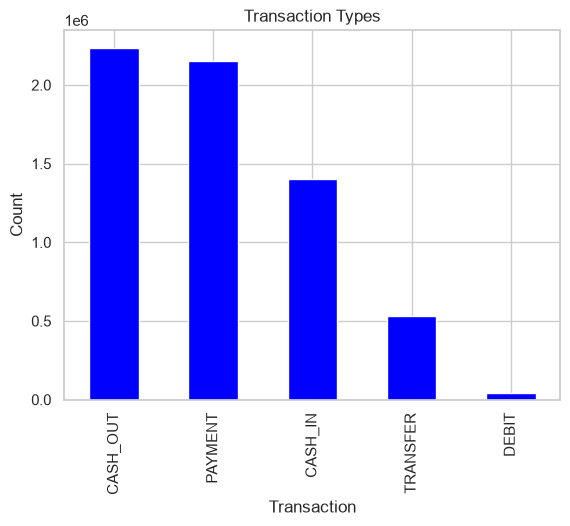

In [25]:
AIML["type"].value_counts().plot(kind = "bar" ,title = "Transaction Types" , color = "blue")
plt.xlabel("Transaction")
plt.ylabel("Count")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

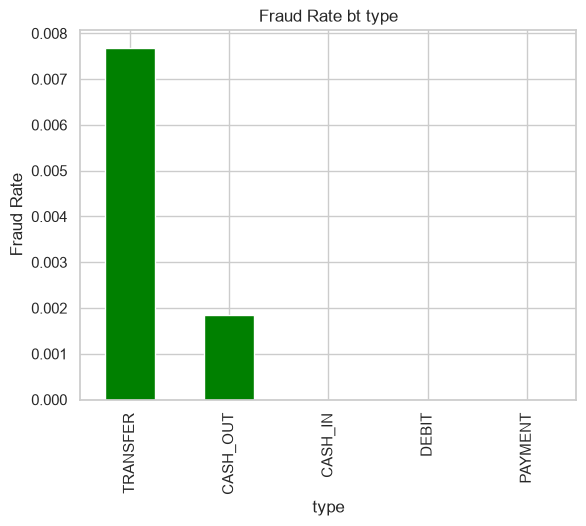

In [27]:
fraud_by_type = AIML.groupby("type")["isFraud"].mean().sort_values(ascending=False)
fraud_by_type.plot(kind ="bar",title="Fraud Rate bt type" , color = "green")
plt.ylabel("Fraud Rate")
plt.show

checking if the visualization above is corret by choosing a random class and check how may fraud in it 

In [28]:

payment = AIML[AIML["type"] == "PAYMENT"]

total_payment = len(payment)

fraud_payment = (payment["isFraud"] == 1).sum()

fraud_rate = (fraud_payment / total_payment) * 100

print("Total payments:", total_payment)
print("Fraudulent payments:", fraud_payment)
print("Fraud rate:", fraud_rate, "%")


Total payments: 2151495
Fraudulent payments: 0
Fraud rate: 0.0 %


In [29]:
AIML["amount"].describe().astype(int)

count     6362620
mean       179861
std        603858
min             0
25%         13389
50%         74871
75%        208721
max      92445516
Name: amount, dtype: int64

In [30]:
AIML["amount"].unique

<bound method Series.unique of 0             9839.64
1             1864.28
2              181.00
3              181.00
4            11668.14
              ...    
6362615     339682.13
6362616    6311409.28
6362617    6311409.28
6362618     850002.52
6362619     850002.52
Name: amount, Length: 6362620, dtype: float64>

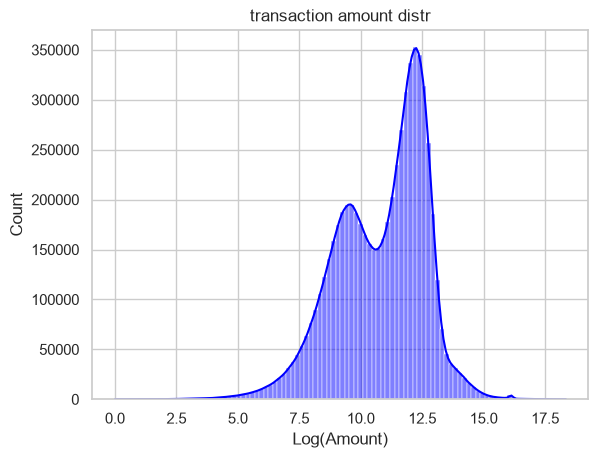

In [31]:
sns.histplot(np.log1p(AIML["amount"]), bins = 100 , kde = True , color = "blue")
plt.title("transaction amount distr")
plt.xlabel("Log(Amount)")
plt.show()

Checking the relationship between (amount) and (isFraud) for amount with values under 50k

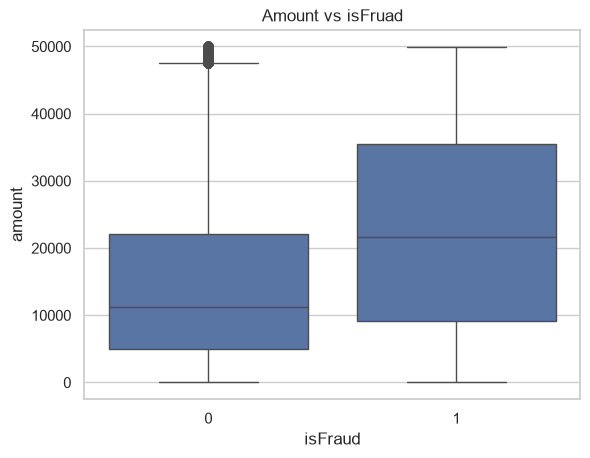

In [32]:
sns.boxplot( data = AIML[AIML["amount"] < 50000] , x ="isFraud" , y = "amount")
plt.title("Amount vs isFruad")
plt.show()

In [33]:
AIML["balanceDiffOrig"] = AIML["oldbalanceOrg"] - AIML["newbalanceOrig"]
AIML["balanceDiffDest"] = AIML["newbalanceDest"] - AIML["oldbalanceDest"]

In [34]:
(AIML["balanceDiffOrig"] < 0).sum()

np.int64(1399253)

In [35]:
(AIML["balanceDiffDest"] < 0).sum()

np.int64(1238864)

Now checking the relationship between the transaction and the time 

In [36]:
AIML["step"].unique()

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
       105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
       118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
       131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
       144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
       157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
       170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 18

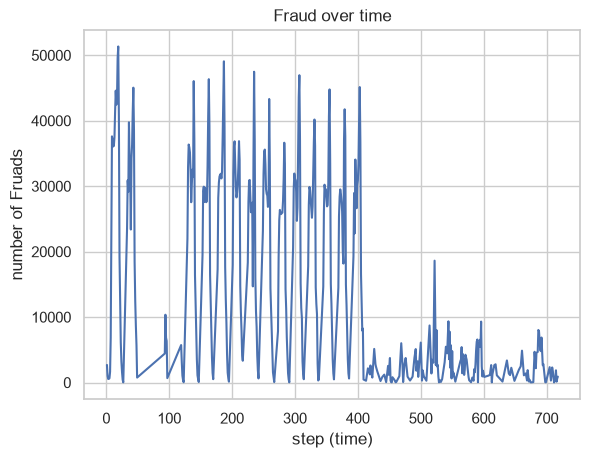

In [37]:
fraud_per_step = AIML[AIML["isFraud"] == 0 ]["step"].value_counts().sort_index()
plt.plot(fraud_per_step.index , fraud_per_step.values , label = "Fraud per step")
plt.xlabel("step (time)")
plt.ylabel("number of Fruads")
plt.title("Fraud over time")
plt.grid(True)
plt.show()

Since it is not time dependent we will drop the(step) column

In [38]:
AIML.drop (columns = "step" , inplace = True)
AIML.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balanceDiffDest
0,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0
2,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,181.00,0.0
3,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,181.00,-21182.0
4,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,11668.14,0.0


Try to find the customers who get the highest transaction rate

In [39]:
top_senders = AIML["nameOrig"].value_counts().head(20)
top_senders

nameOrig
C2098525306    3
C400299098     3
C1999539787    3
C1065307291    3
C545315117     3
C1976208114    3
C1784010646    3
C1530544995    3
C1902386530    3
C1677795071    3
C724452879     3
C1832548028    3
C2051359467    3
C363736674     3
C1462946854    3
C835773569     2
C1101598632    2
C1032568028    2
C1892869131    2
C1859823482    2
Name: count, dtype: int64

In [40]:
top_receivers = AIML["nameDest"].value_counts().head(20)
top_receivers

nameDest
C1286084959    113
C985934102     109
C665576141     105
C2083562754    102
C248609774     101
C1590550415    101
C451111351      99
C1789550256     99
C1360767589     98
C1023714065     97
C977993101      96
C97730845       96
C392292416      95
C1899073220     92
C306206744      91
C1234776885     90
C1782113663     90
C998351292      89
C716083600      89
C909295153      88
Name: count, dtype: int64

In [41]:
fraud_types = AIML[AIML["type"].isin(["TRANSFER" ,"CASH_OUT"])]

In [42]:
fraud_types["type"].value_counts()

type
CASH_OUT    2237500
TRANSFER     532909
Name: count, dtype: int64

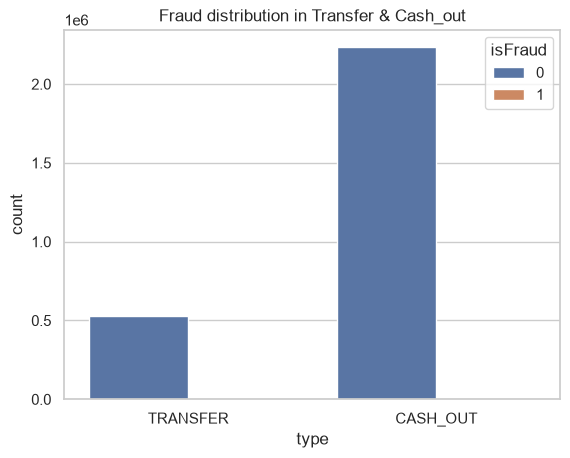

In [43]:
sns.countplot(data = fraud_types , x ="type" , hue = "isFraud")
plt.title("Fraud distribution in Transfer & Cash_out")
plt.show()

checking the relation for each column 

In [44]:
corr = AIML[["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFraud"]]


filter the customners with zero balance after transfer 

In [45]:
zero_after_transfer = AIML[
    (AIML["oldbalanceOrg"] > 0)& 
    (AIML["newbalanceOrig"] == 0)&
    (AIML["type"].isin(["TRANSFER" , "CASH_OUT"]))
]

In [46]:
len(zero_after_transfer)

1188074

In [59]:
AIML["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

Training the model 

In [49]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer  
from sklearn.preprocessing import OneHotEncoder 

In [52]:
AIML.head(10)

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balanceDiffDest
0,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.0,0.00,0,0,9839.64,0.00
1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.0,0.00,0,0,1864.28,0.00
2,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.0,0.00,1,0,181.00,0.00
3,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.0,0.00,1,0,181.00,-21182.00
4,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.0,0.00,0,0,11668.14,0.00
5,PAYMENT,7817.71,C90045638,53860.00,46042.29,M573487274,0.0,0.00,0,0,7817.71,0.00
6,PAYMENT,7107.77,C154988899,183195.00,176087.23,M408069119,0.0,0.00,0,0,7107.77,0.00
7,PAYMENT,7861.64,C1912850431,176087.23,168225.59,M633326333,0.0,0.00,0,0,7861.64,0.00
8,PAYMENT,4024.36,C1265012928,2671.00,0.00,M1176932104,0.0,0.00,0,0,2671.00,0.00
9,DEBIT,5337.77,C712410124,41720.00,36382.23,C195600860,41898.0,40348.79,0,0,5337.77,-1549.21


In [53]:
AIML_model = AIML.drop(["nameOrig" , "nameDest" , "isFlaggedFraud"], axis = 1)

In [54]:
AIML_model.head(10)

,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,balanceDiffOrig,balanceDiffDest
0,PAYMENT,9839.64,170136.00,160296.36,0.0,0.00,0,9839.64,0.00
1,PAYMENT,1864.28,21249.00,19384.72,0.0,0.00,0,1864.28,0.00
2,TRANSFER,181.00,181.00,0.00,0.0,0.00,1,181.00,0.00
3,CASH_OUT,181.00,181.00,0.00,21182.0,0.00,1,181.00,-21182.00
4,PAYMENT,11668.14,41554.00,29885.86,0.0,0.00,0,11668.14,0.00
5,PAYMENT,7817.71,53860.00,46042.29,0.0,0.00,0,7817.71,0.00
6,PAYMENT,7107.77,183195.00,176087.23,0.0,0.00,0,7107.77,0.00
7,PAYMENT,7861.64,176087.23,168225.59,0.0,0.00,0,7861.64,0.00
8,PAYMENT,4024.36,2671.00,0.00,0.0,0.00,0,2671.00,0.00
9,DEBIT,5337.77,41720.00,36382.23,41898.0,40348.79,0,5337.77,-1549.21


In [55]:
AIML_model.columns

Index(['type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest',
       'newbalanceDest', 'isFraud', 'balanceDiffOrig', 'balanceDiffDest'],
      dtype='str')

In [64]:
categories = ["type"]
numeric = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest']

In [65]:
y = AIML_model["isFraud"]
X = AIML_model.drop("isFraud" ,axis =1)

In [66]:
X_train ,X_test , y_train ,y_test = train_test_split(X, y,test_size= 0.3 ,stratify= y)

In [68]:
preprocessor = ColumnTransformer(
    transformers= [
        ("num" , StandardScaler() , numeric),
        ("cat" , OneHotEncoder(drop = "first"), categories)
    ],

    remainder= "drop"
)

In [69]:
pipeline = Pipeline([
    ("prep", preprocessor),
    ("cls" , LogisticRegression(class_weight="balanced" , max_iter= 1000))
])

In [70]:
pipeline.fit(X_train ,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('cls', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['type','amount','oldbalanceOrg',...,'newbalanceDest','balanceDiffOrig', 'balanceDiffDest']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'

In [71]:
y_pred = pipeline.predict(X_test)

In [73]:
print(classification_report(y_test , y_pred))

              precision    recall  f1-score   support

           0       1.00      0.94      0.97   1906322
           1       0.02      0.93      0.04      2464

    accuracy                           0.94   1908786
   macro avg       0.51      0.94      0.51   1908786
weighted avg       1.00      0.94      0.97   1908786



In [74]:
confusion_matrix(y_test,y_pred)

array([[1798301,  108021],
       [    176,    2288]])

In [76]:
pipeline.score(X_test,y_test) * 100

94.33163277601575

In [77]:
import joblib
joblib.dump(pipeline, "Fraud_detection_pipeline.pkl")

['Fraud_detection_pipeline.pkl']